In [ ]:
# GRAPH ALGORITHMS: BFS, DFS AND MAZE SOLVER
# ============================================================
import networkx as nx
import matplotlib.pyplot as plt
print("Libraries imported successfully!")

Libraries imported successfully!


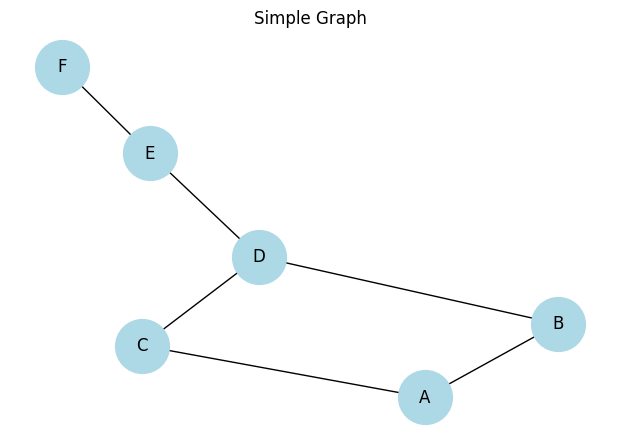

In [ ]:
# ------------------------------------------------------------
# CODE 1: CREATE A SIMPLE GRAPH
# ------------------------------------------------------------
G = nx.Graph()
G.add_edges_from([
    ("A", "B"),
    ("A", "C"),
    ("B", "D"),
    ("C", "D"),
    ("D", "E"),
    ("E", "F")
])
plt.figure(figsize=(6, 4))
nx.draw(G, with_labels=True, node_color="lightblue",
        node_size=1500, font_size=12)
plt.title("Simple Graph")
plt.show()

In [ ]:
# ------------------------------------------------------------
# CODE 2: RUN BFS AND DFS
# ------------------------------------------------------------
bfs_order = list(nx.bfs_tree(G, source="A"))
dfs_order = list(nx.dfs_preorder_nodes(G, source="A"))
print("BFS order:", bfs_order)
print("DFS order:", dfs_order)

BFS order: ['A', 'B', 'C', 'D', 'E', 'F']
DFS order: ['A', 'B', 'D', 'C', 'E', 'F']


In [ ]:
# ------------------------------------------------------------
# CODE 3: CREATE A MAZE
# 0 = Open path, 1 = Wall
# ------------------------------------------------------------

maze = [
    [0, 0, 1, 0, 0],
    [1, 0, 1, 0, 1],
    [0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0]
]
print("\nMaze:")
for row in maze:
    print(row)


Maze:
[0, 0, 1, 0, 0]
[1, 0, 1, 0, 1]
[0, 0, 0, 0, 0]
[0, 1, 1, 1, 0]
[0, 0, 0, 0, 0]


In [ ]:
# ------------------------------------------------------------
# CODE 4: CONVERT THE MAZE INTO A GRAPH
# ------------------------------------------------------------
G_maze = nx.Graph()

rows = len(maze)
cols = len(maze[0])

for r in range(rows):
    for c in range(cols):

        # Ignore walls
        if maze[r][c] == 1:
            continue

        # Add walkable cell
        G_maze.add_node((r, c))

        # Check up, down, left and right
        for dr, dc in [(0, 1), (1, 0), (0, -1), (-1, 0)]:
            nr = r + dr
            nc = c + dc

            if (0 <= nr < rows and
                0 <= nc < cols and
                maze[nr][nc] == 0):

                G_maze.add_edge((r, c), (nr, nc))

print("\nWalkable cells:", G_maze.number_of_nodes())
print("Connections:", G_maze.number_of_edges())


Walkable cells: 18
Connections: 18


In [ ]:
# ------------------------------------------------------------
# CODE 5: SOLVE THE MAZE USING BFS
# ------------------------------------------------------------
start = (0, 0)
end = (4, 4)

path = nx.shortest_path(
    G_maze,
    source=start,
    target=end
)

print("\nBFS shortest path:")
print(path)
print("Number of moves:", len(path) - 1)


BFS shortest path:
[(0, 0), (0, 1), (1, 1), (2, 1), (2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]
Number of moves: 8


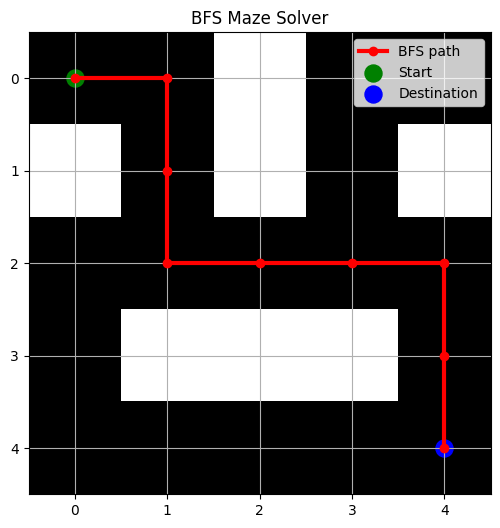

In [ ]:
# ------------------------------------------------------------
# CODE 6: VISUALIZE THE BFS SOLUTION
# ------------------------------------------------------------

plt.figure(figsize=(6, 6))
plt.imshow(maze, cmap="binary_r", origin="upper")

path_rows = [p[0] for p in path]
path_cols = [p[1] for p in path]

plt.plot(path_cols, path_rows, "ro-", linewidth=3,
         label="BFS path")

plt.scatter(start[1], start[0], color="green",
            s=150, label="Start")

plt.scatter(end[1], end[0], color="blue",
            s=150, label="Destination")

plt.xticks(range(cols))
plt.yticks(range(rows))
plt.grid(True)
plt.legend()
plt.title("BFS Maze Solver")
plt.show()


In [ ]:
# ------------------------------------------------------------
# CODE 7: SOLVE THE MAZE USING DFS
# ------------------------------------------------------------
def dfs_solve(graph, start, end):

    stack = [(start, [start])]
    visited = set()

    while stack:

        node, route = stack.pop()

        if node == end:
            return route

        if node in visited:
            continue

        visited.add(node)

        for neighbour in graph.neighbors(node):
            if neighbour not in visited:
                stack.append((neighbour, route + [neighbour]))

    return None


dfs_route = dfs_solve(G_maze, start, end)

print("\nDFS route:")
print(dfs_route)

if dfs_route:
    print("DFS number of moves:", len(dfs_route) - 1)
else:
    print("No route found.")


DFS route:
[(0, 0), (0, 1), (1, 1), (2, 1), (2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]
DFS number of moves: 8


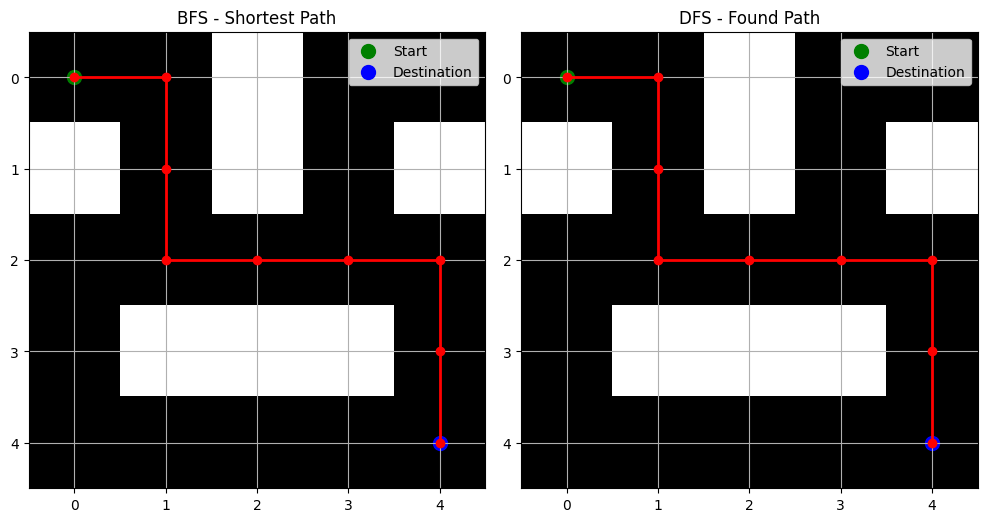

In [ ]:
# ------------------------------------------------------------
# CODE 8: COMPARE BFS AND DFS VISUALLY
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, route, title in [
    (axes[0], path, "BFS - Shortest Path"),
    (axes[1], dfs_route, "DFS - Found Path")
]:

    ax.imshow(maze, cmap="binary_r", origin="upper")

    route_rows = [p[0] for p in route]
    route_cols = [p[1] for p in route]

    ax.plot(route_cols, route_rows, "ro-", linewidth=2)
    ax.scatter(0, 0, color="green", s=100, label="Start")
    ax.scatter(4, 4, color="blue", s=100, label="Destination")

    ax.set_title(title)
    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()


**Pandas File Manipulation**

In [ ]:
import pandas as pd

# Sample dataset
df = pd.DataFrame({
    "Name": ["Amit", "Ravi", "Neha", "Priya", "Rahul"],
    "Age": [25, 30, 22, 28, 35],
    "Salary": [30000, 50000, 25000, 60000, 70000],
    "Department": ["IT", "HR", "IT", "Sales", "HR"]
})
df.head()


,Name,Age,Salary,Department
0,Amit,25,30000,IT
1,Ravi,30,50000,HR
2,Neha,22,25000,IT
3,Priya,28,60000,Sales
4,Rahul,35,70000,HR


In [ ]:
# 3. Filter salary above 40000
df[df["Salary"] > 40000]

,Name,Age,Salary,Department
1,Ravi,30,50000,HR
3,Priya,28,60000,Sales
4,Rahul,35,70000,HR


In [ ]:
# 4. Filter age below 30
df[df["Age"] < 30]

,Name,Age,Salary,Department
0,Amit,25,30000,IT
2,Neha,22,25000,IT
3,Priya,28,60000,Sales


In [ ]:
# 5. Filter IT employees
print(df[df["Department"] == "IT"])

   Name  Age  Salary Department
0  Amit   25   30000         IT
2  Neha   22   25000         IT


In [ ]:
# 6. Filter salary between 30000 and 60000
print(df[df["Salary"].between(30000, 60000)])


    Name  Age  Salary Department
0   Amit   25   30000         IT
1   Ravi   30   50000         HR
3  Priya   28   60000      Sales


In [ ]:
# 7. Filter multiple conditions using AND
print(df[(df["Age"] > 25) & (df["Salary"] > 40000)])

    Name  Age  Salary Department
1   Ravi   30   50000         HR
3  Priya   28   60000      Sales
4  Rahul   35   70000         HR


In [ ]:
# 8. Filter using OR
print(df[(df["Department"] == "HR") | (df["Department"] == "IT")])

    Name  Age  Salary Department
0   Amit   25   30000         IT
1   Ravi   30   50000         HR
2   Neha   22   25000         IT
4  Rahul   35   70000         HR


In [ ]:
# 9. Filter using isin()
print(df[df["Department"].isin(["IT", "Sales"])])

    Name  Age  Salary Department
0   Amit   25   30000         IT
2   Neha   22   25000         IT
3  Priya   28   60000      Sales


In [ ]:
# 10. Filter names containing 'a'
print(df[df["Name"].str.contains("a", case=False)])

    Name  Age  Salary Department
0   Amit   25   30000         IT
1   Ravi   30   50000         HR
2   Neha   22   25000         IT
3  Priya   28   60000      Sales
4  Rahul   35   70000         HR


In [ ]:
# 11. Sort by salary ascending
print(df.sort_values("Salary"))


    Name  Age  Salary Department
2   Neha   22   25000         IT
0   Amit   25   30000         IT
1   Ravi   30   50000         HR
3  Priya   28   60000      Sales
4  Rahul   35   70000         HR


In [ ]:
# 12. Sort by salary descending
print(df.sort_values("Salary", ascending=False))

    Name  Age  Salary Department
4  Rahul   35   70000         HR
3  Priya   28   60000      Sales
1   Ravi   30   50000         HR
0   Amit   25   30000         IT
2   Neha   22   25000         IT


In [ ]:
# 14. Sort by department and salary
print(df.sort_values(["Department", "Salary"]))


    Name  Age  Salary Department
1   Ravi   30   50000         HR
4  Rahul   35   70000         HR
2   Neha   22   25000         IT
0   Amit   25   30000         IT
3  Priya   28   60000      Sales


In [ ]:
# 15. Select a single column
print(df["Name"])

0     Amit
1     Ravi
2     Neha
3    Priya
4    Rahul
Name: Name, dtype: object
